# Procgen Maze 训练结果可视化

用于可视化 Procgen Maze 环境中的训练结果：
- PPO（基础版本，无内在奖励）
- PPO+RND（带 RND 内在奖励）
- PPO+ICM（带 ICM 内在奖励）
- PPO+NS（Boundary Novelty Search）
- PPO+BANS（Boundary Aware Novelty Search）


In [23]:
# ==== 基础依赖 ====
# 如果第一次用，可以先在环境里 pip 一下：
# !pip install tensorboard

import os
from tensorboard.backend.event_processing import event_accumulator
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# 使用 seaborn style（如果可用）
try:
    plt.style.use("seaborn-v0_8")
except:
    try:
        plt.style.use("seaborn")
    except:
        pass

# ==== 自动检测项目根目录 ====
# 当前工作目录通常是项目根目录
PROJECT_ROOT = os.path.dirname(os.path.abspath(""))
# Procgen Maze 的日志位于 boundary_ns_rl/logs 目录下
LOGS_DIR = os.path.join(PROJECT_ROOT, "boundary_ns_rl", "logs")

# ==== Procgen Maze 的 run ====
RUNS = {
    # PPO（基础版本，无内在奖励）
    "procgen_maze_ppo_2": os.path.join(LOGS_DIR, "procgen_maze_ppo", "PPO_2"),
    # PPO+RND（带 RND 内在奖励）
    "procgen_maze_ppo_rnd_4": os.path.join(LOGS_DIR, "procgen_maze_ppo_rnd", "PPO_4"),  # 最新 RND 结果
    # PPO+ICM（带 ICM 内在奖励）
    "procgen_maze_ppo_icm_1": os.path.join(LOGS_DIR, "procgen_maze_ppo_icm", "PPO_1"),
    # PPO+NS（Boundary Novelty Search）
    "procgen_maze_ppo_ns_3": os.path.join(LOGS_DIR, "procgen_maze_ppo_ns", "PPO_3"),
    # PPO+BANS（Boundary Aware Novelty Search）
    "procgen_maze_ppo_bans_1": os.path.join(LOGS_DIR, "procgen_maze_ppo_bans", "PPO_1"),
    # 如果有多个运行，可以添加更多
    # "procgen_maze_ppo_2": os.path.join(LOGS_DIR, "procgen_maze_ppo", "PPO_2"),
    # "procgen_maze_ppo_icm_2": os.path.join(LOGS_DIR, "procgen_maze_ppo_icm", "PPO_2"),
}

# 检查哪些 run 存在
existing_runs = {}
for name, path in RUNS.items():
    if os.path.isdir(path):
        existing_runs[name] = path
    else:
        print(f"[WARN] Run not found: {name} at {path}")

print(f"Found {len(existing_runs)} runs:")
for name in existing_runs.keys():
    print(f"  - {name}")

RUNS = existing_runs


Found 5 runs:
  - procgen_maze_ppo_2
  - procgen_maze_ppo_rnd_4
  - procgen_maze_ppo_icm_1
  - procgen_maze_ppo_ns_3
  - procgen_maze_ppo_bans_1


In [24]:
# ===== 查看所有可用的 tags =====
if len(RUNS) > 0:
    first_run = list(RUNS.values())[0]
    ea = event_accumulator.EventAccumulator(first_run)
    ea.Reload()
    all_tags = ea.Tags().get("scalars", [])
    print("所有可用的 scalar tags:")
    print("=" * 60)
    for tag in sorted(all_tags):
        print(f"  - {tag}")
    print("=" * 60)
    
    # 检查是否有 intrinsic/external reward 相关的 tags
    intrinsic_tags = [t for t in all_tags if 'intrinsic' in t.lower()]
    external_tags = [t for t in all_tags if 'external' in t.lower()]
    episode_reward_tags = [t for t in all_tags if 'episode' in t.lower() and 'reward' in t.lower()]
    
    print(f"\nIntrinsic reward tags: {intrinsic_tags if intrinsic_tags else '未找到'}")
    print(f"External reward tags: {external_tags if external_tags else '未找到'}")
    print(f"Episode reward tags: {episode_reward_tags if episode_reward_tags else '未找到'}")


所有可用的 scalar tags:
  - eval/mean_ep_length
  - eval/mean_reward
  - rollout/episode_external_reward
  - rollout/episode_intrinsic_reward
  - rollout/total_reward_cumulative
  - time/fps
  - train/approx_kl
  - train/clip_fraction
  - train/clip_range
  - train/entropy_loss
  - train/explained_variance
  - train/learning_rate
  - train/loss
  - train/policy_gradient_loss
  - train/value_loss

Intrinsic reward tags: ['rollout/episode_intrinsic_reward']
External reward tags: ['rollout/episode_external_reward']
Episode reward tags: ['rollout/episode_external_reward', 'rollout/episode_intrinsic_reward']


In [25]:
def load_scalar_from_event(run_dir, tag, silent=False):
    """
    从一个 TensorBoard run 目录中，读取指定 tag 的 scalar 序列。
    返回：
      steps: np.array
      values: np.array
    """
    if not os.path.isdir(run_dir):
        raise FileNotFoundError(f"Run dir not found: {run_dir}")
    
    ea = event_accumulator.EventAccumulator(
        run_dir,
        size_guidance={"scalars": 0}  # 加载所有 scalar
    )
    ea.Reload()
    
    available = ea.Tags().get("scalars", [])
    if tag not in available:
        if not silent:
            print(f"[WARN] tag '{tag}' not found in {run_dir}")
        return None, None
    
    events = ea.Scalars(tag)
    steps = np.array([e.step for e in events])
    values = np.array([e.value for e in events])
    return steps, values


# 创建友好的名称映射
run_name_mapping = {
    "procgen_maze_ppo_2": "PPO(vanilla)",
    "procgen_maze_ppo_rnd_4": "PPO+RND",
    "procgen_maze_ppo_icm_1": "PPO+ICM",
    "procgen_maze_ppo_ns_3": "PPO+NS",
    "procgen_maze_ppo_bans_1": "PPO+BANS",
}

# 固定颜色映射，便于区分曲线
color_map = {
    "PPO(vanilla)": "tab:blue",
    "PPO+RND": "tab:orange",
    "PPO+ICM": "tab:green",
    "PPO+NS": "gold",
    "PPO+BANS": "tab:purple",
}

def plot_tag_for_runs(tag, runs_dict, title=None, xlabel="Episode", ylabel=None):
    """
    在一张图上绘制多个 run 的同一个 tag 曲线。
    横坐标自动转换为 Episode。
    """
    plt.figure(figsize=(10, 6))
    
    for name, path in runs_dict.items():
        steps, vals = load_scalar_from_event(path, tag, silent=True)
        if steps is None:
            continue
        
        # 获取 episode_count 来作为横坐标
        episode_steps, episode_counts = load_scalar_from_event(path, "rollout/episode_count", silent=True)
        
        # 对齐到 episodes
        if episode_steps is not None and len(episode_counts) > 0:
            # 如果两个数据集的长度相同且 steps 接近，直接使用
            if len(steps) == len(episode_steps) and np.allclose(steps, episode_steps, rtol=0.1):
                x_data = episode_counts
            else:
                # 需要对齐：找到每个 reward 数据点对应的 episode_count
                aligned_episodes = []
                aligned_vals = []
                for i, step in enumerate(steps):
                    idx = np.argmin(np.abs(episode_steps - step))
                    if abs(episode_steps[idx] - step) < 5000:
                        aligned_episodes.append(episode_counts[idx])
                        aligned_vals.append(vals[i])
                if len(aligned_episodes) > 0:
                    x_data = np.array(aligned_episodes)
                    vals = np.array(aligned_vals)
                else:
                    # 对齐失败，使用数据点索引作为 episode 编号
                    x_data = np.arange(1, len(vals) + 1)
        else:
            # 没有 episode_count，使用数据点索引作为 episode 编号
            # 因为 reward 数据是在每个 episode 结束时记录的，所以每个数据点对应一个 episode
            x_data = np.arange(1, len(vals) + 1)
        
        # 使用友好的名称映射
        display_name = run_name_mapping.get(name, name)
        color = color_map.get(display_name, None)
        plt.plot(x_data, vals, label=display_name, linewidth=1.5, alpha=0.8, color=color)
    
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel(ylabel if ylabel is not None else tag, fontsize=12)
    plt.title(title if title is not None else tag, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


# 可选：查看某个 run 里有哪些 tag
# if len(RUNS) > 0:
#     first_run = list(RUNS.values())[0]
#     ea = event_accumulator.EventAccumulator(first_run)
#     ea.Reload()
#     print("Available tags:", ea.Tags()["scalars"])


查找 reward 相关的指标...
  ✓ 找到: rollout/episode_external_reward (114 个数据点)
  ✓ 找到: rollout/episode_intrinsic_reward (114 个数据点)
  ✓ 找到: rollout/total_reward_cumulative (114 个数据点)
[WARN] tag 'rollout/episode_total_reward' not found in /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/boundary_ns_rl/logs/procgen_maze_ppo/PPO_2
  ✗ 未找到: rollout/episode_total_reward
[WARN] tag 'rollout/ep_rew_mean' not found in /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/boundary_ns_rl/logs/procgen_maze_ppo/PPO_2
  ✗ 未找到: rollout/ep_rew_mean
[WARN] tag 'rollout/ep_len_mean' not found in /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/boundary_ns_rl/logs/procgen_maze_ppo/PPO_2
  ✗ 未找到: rollout/ep_len_mean

找到 3 个 reward 指标



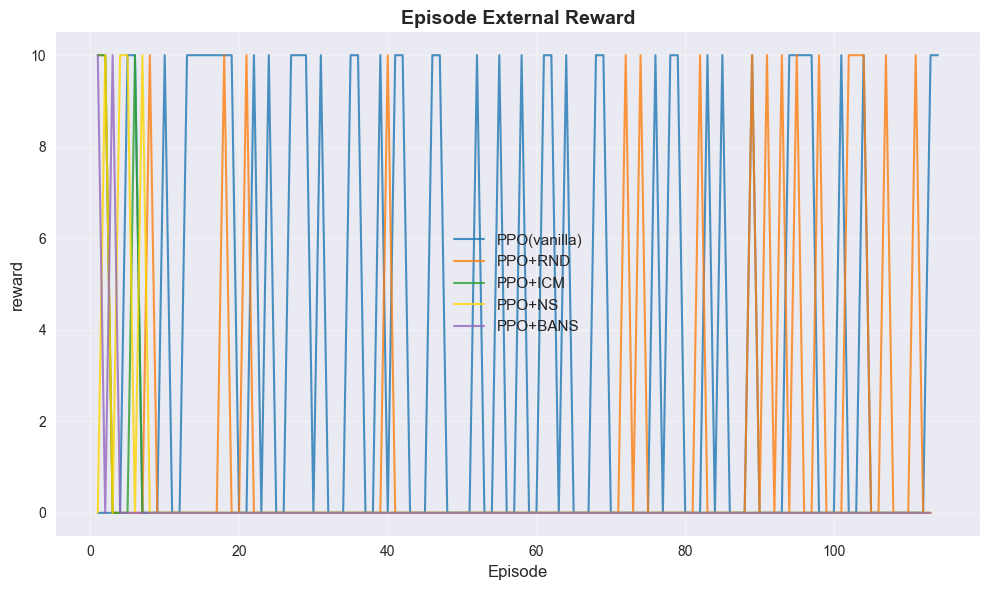

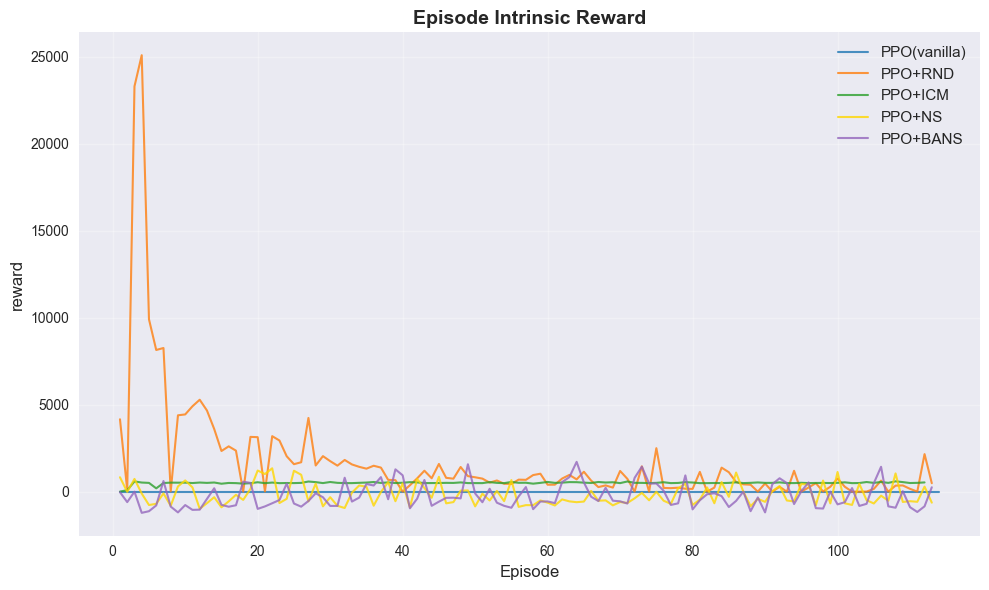

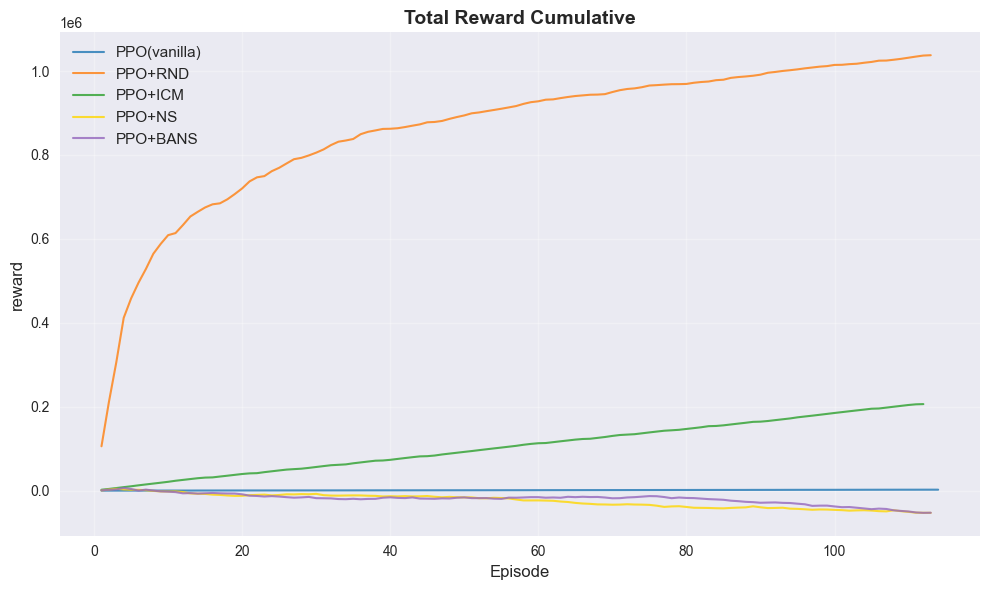


绘制对比图: PPO(vanilla), PPO+RND, PPO+ICM, PPO+NS, PPO+BANS

检查每个 run 的 reward 相关 tags:
------------------------------------------------------------

PPO(vanilla):
  - eval/mean_reward: 20 个数据点
  - rollout/episode_external_reward: 114 个数据点
  - rollout/episode_intrinsic_reward: 114 个数据点
  - rollout/total_reward_cumulative: 114 个数据点
  - rollout/episode_count: 未找到 ✗

PPO+RND:
  - eval/mean_reward: 20 个数据点
  - rollout/episode_external_reward: 113 个数据点
  - rollout/episode_intrinsic_reward: 113 个数据点
  - rollout/total_reward_cumulative: 113 个数据点
  - rollout/episode_count: 未找到 ✗

PPO+ICM:
  - eval/mean_reward: 20 个数据点
  - rollout/episode_external_reward: 112 个数据点
  - rollout/episode_intrinsic_reward: 112 个数据点
  - rollout/total_reward_cumulative: 112 个数据点
  - rollout/episode_count: 未找到 ✗

PPO+NS:
  - eval/mean_reward: 20 个数据点
  - rollout/episode_external_reward: 114 个数据点
  - rollout/episode_intrinsic_reward: 114 个数据点
  - rollout/total_reward_cumulative: 114 个数据点
  - rollout/episode_count: 未找到 ✗

P

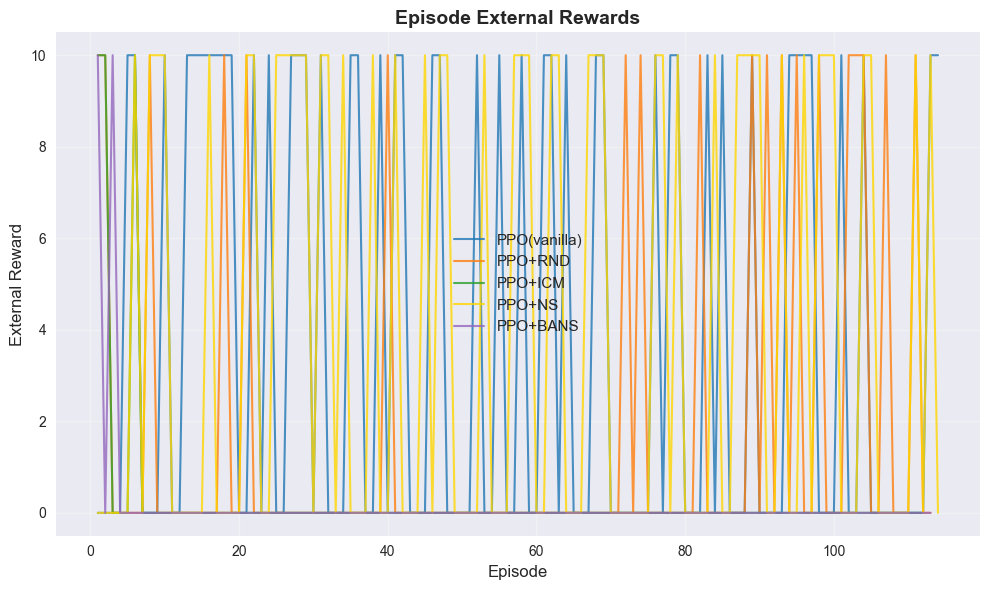


绘制 Episode Intrinsic Rewards...
  [OK] PPO(vanilla): 114 个数据点 (使用索引作为 episode)
  [OK] PPO+RND: 113 个数据点 (使用索引作为 episode)
  [OK] PPO+ICM: 112 个数据点 (使用索引作为 episode)
  [OK] PPO+NS: 114 个数据点 (使用索引作为 episode)
  [OK] PPO+BANS: 113 个数据点 (使用索引作为 episode)


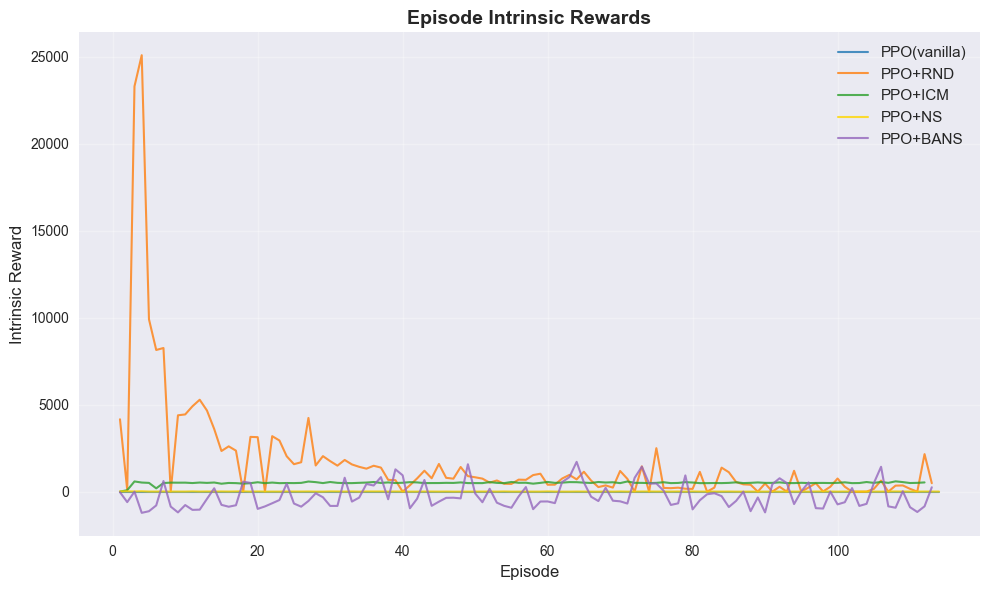


绘制 Total Reward Cumulative...
  [OK] PPO(vanilla): 114 个数据点 (使用索引作为 episode)
  [OK] PPO+RND: 113 个数据点 (使用索引作为 episode)
  [OK] PPO+ICM: 112 个数据点 (使用索引作为 episode)
  [OK] PPO+NS: 114 个数据点 (使用索引作为 episode)
  [OK] PPO+BANS: 113 个数据点 (使用索引作为 episode)


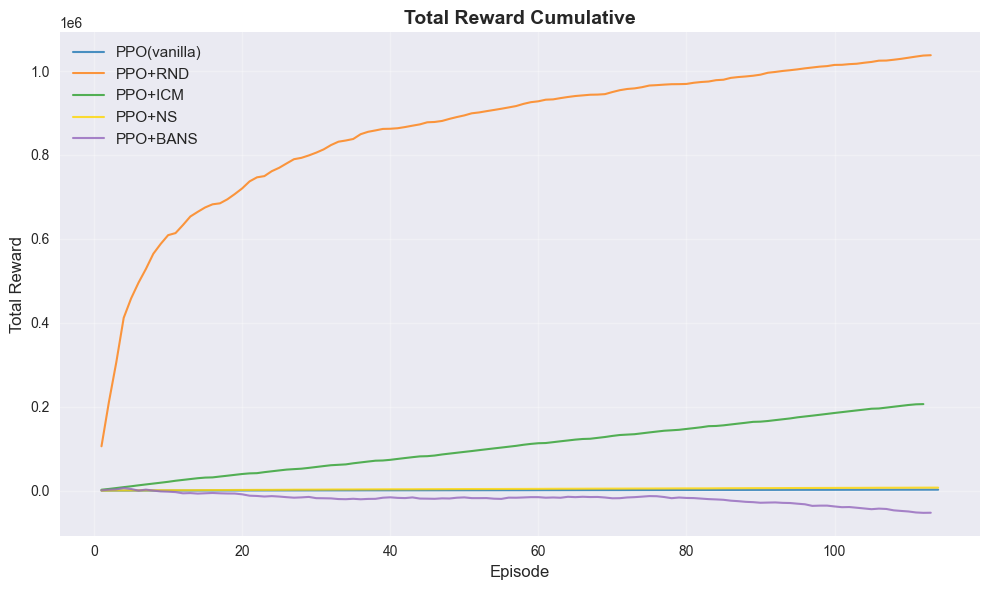


为每个 run 绘制 Intrinsic/External/Total Rewards 对比图...


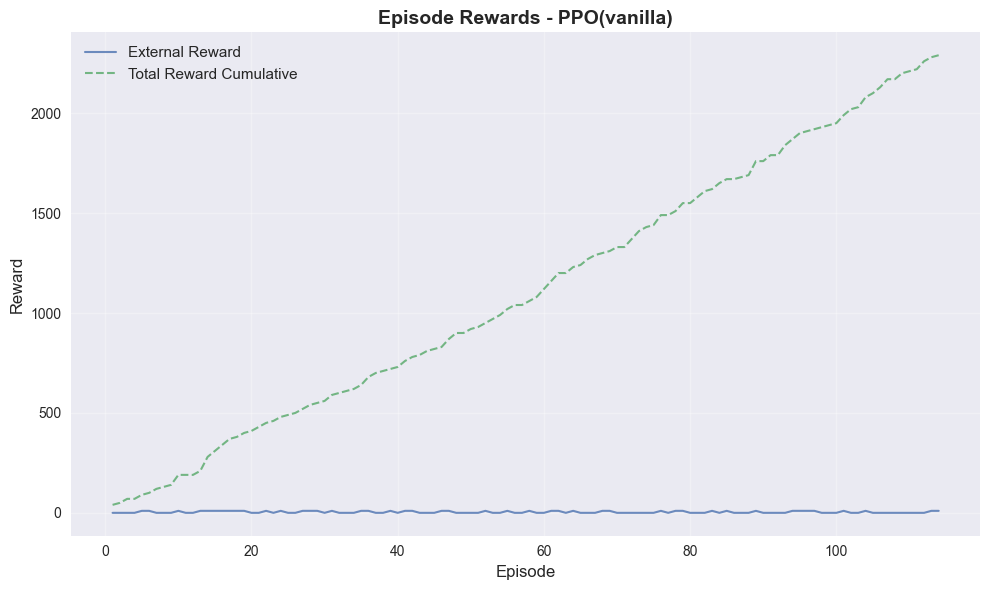

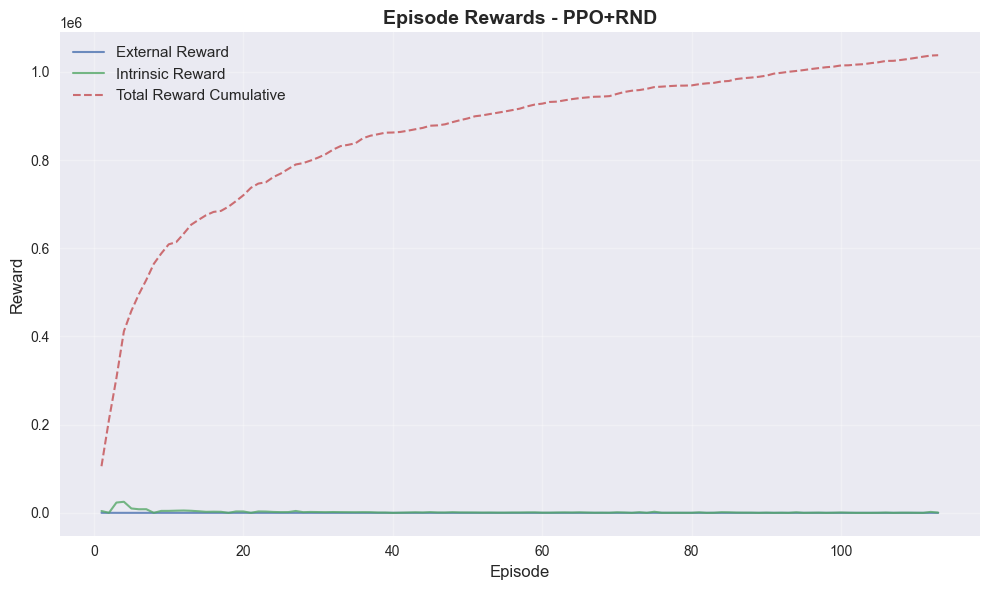

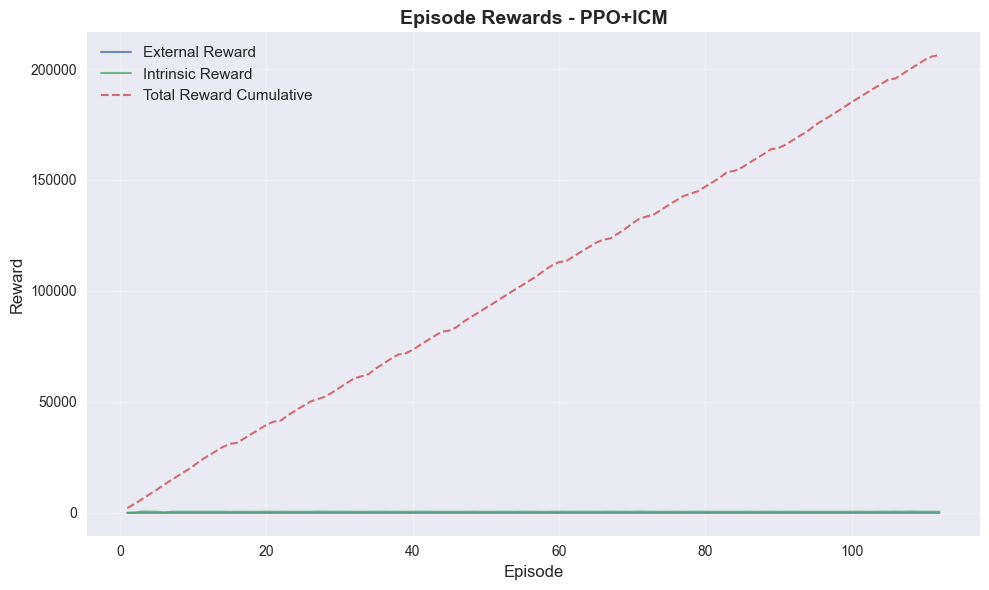

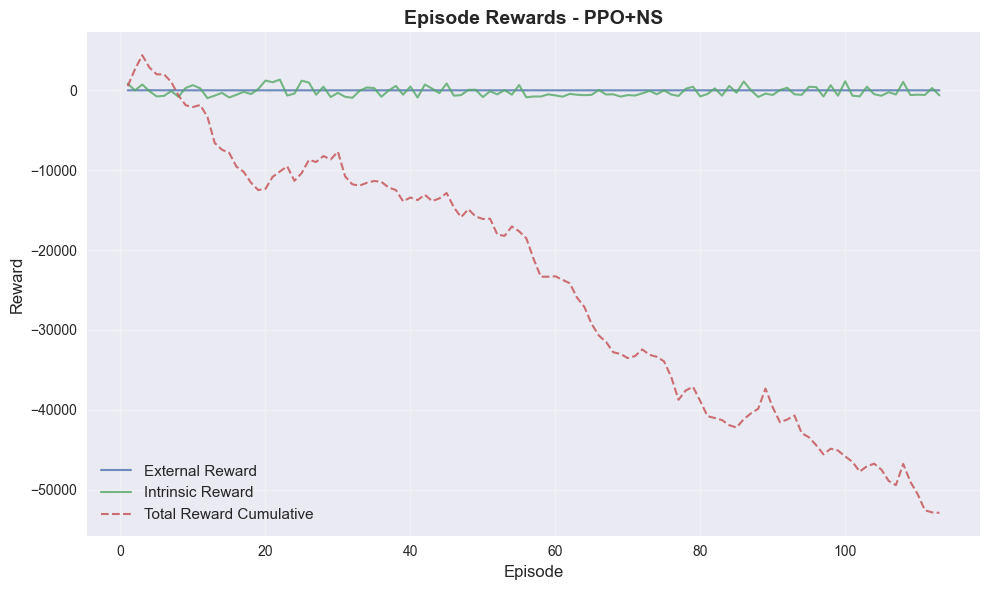

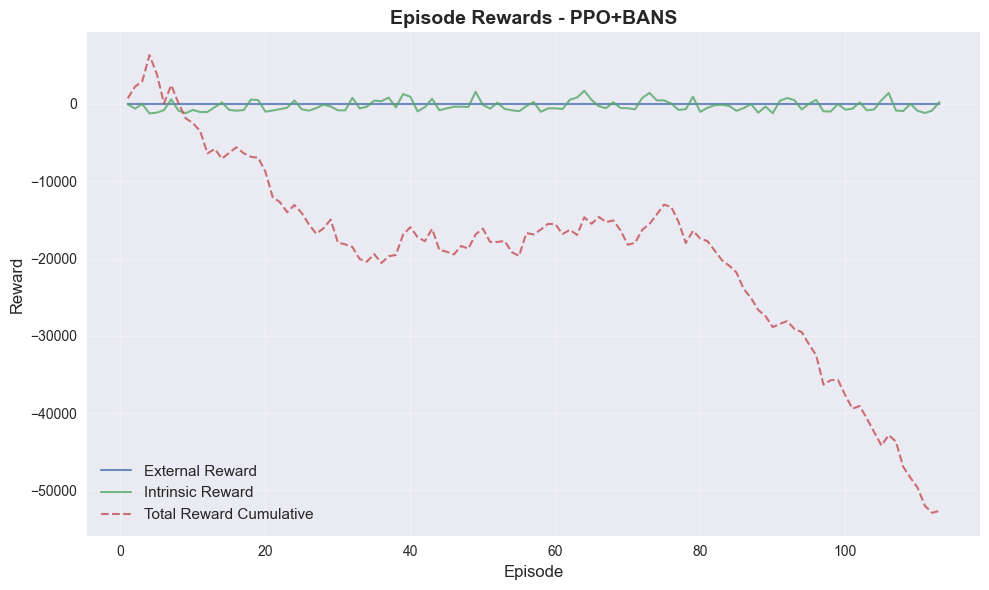

In [26]:
# ===== 绘制 Intrinsic/External/Total Rewards =====
# 这些指标是在训练脚本中通过 RewardLoggingCallback 记录的
# 注意：
# - episode_external_reward: 当前 episode 的 external reward（不累积）
# - episode_intrinsic_reward: 当前 episode 的 intrinsic reward（不累积）
# - total_reward_cumulative: 累积的 total reward（所有 episode 的总和）
# - PPO（无内在奖励）：intrinsic reward = 0
# - PPO+RND：intrinsic reward > 0（基于预测误差）
# - PPO+ICM：intrinsic reward > 0（基于前向模型预测误差）

reward_tags = {
    "rollout/episode_external_reward": "Episode External Reward",
    "rollout/episode_intrinsic_reward": "Episode Intrinsic Reward", 
    "rollout/total_reward_cumulative": "Total Reward Cumulative",
    "rollout/episode_total_reward": "Episode Total Reward",  # 兼容旧版本的 tag
    "rollout/ep_rew_mean": "Rollout Episode Reward Mean",  # SB3 默认的 rollout reward
    "rollout/ep_len_mean": "Rollout Episode Length Mean",
}

print("查找 reward 相关的指标...")
print("=" * 60)

found_tags = {}
for tag, title in reward_tags.items():
    if len(RUNS) > 0:
        first_run = list(RUNS.values())[0]
        steps, vals = load_scalar_from_event(first_run, tag)
        if steps is not None:
            print(f"  ✓ 找到: {tag} ({len(steps)} 个数据点)")
            found_tags[tag] = title
        else:
            print(f"  ✗ 未找到: {tag}")

print("\n" + "=" * 60)
print(f"找到 {len(found_tags)} 个 reward 指标\n")

# 绘制找到的指标（每个 run 单独绘制）
for tag, title in found_tags.items():
    if tag != "rollout/episode_total_reward":  # 跳过旧版本的 tag，避免重复
        plot_tag_for_runs(tag, RUNS, title=title, ylabel="reward")

# ===== 对比图：PPO(vanilla), PPO+RND, PPO+ICM, PPO+NS, PPO+BANS =====
# 参考 Visualization.ipynb 的风格

comparison_runs = {
    "PPO(vanilla)": os.path.join(LOGS_DIR, "procgen_maze_ppo", "PPO_2"),
    "PPO+RND": os.path.join(LOGS_DIR, "procgen_maze_ppo_rnd", "PPO_4"),
    "PPO+ICM": os.path.join(LOGS_DIR, "procgen_maze_ppo_icm", "PPO_1"),
    "PPO+NS": os.path.join(LOGS_DIR, "procgen_maze_ppo_ns", "PPO_1"),
    "PPO+BANS": os.path.join(LOGS_DIR, "procgen_maze_ppo_bans", "PPO_1"),
}

# 过滤出存在的运行
existing_comparison_runs = {}
for name, path in comparison_runs.items():
    if os.path.isdir(path):
        existing_comparison_runs[name] = path
    else:
        print(f"[WARN] Run not found: {name} at {path}")

if len(existing_comparison_runs) > 0:
    print("\n" + "=" * 60)
    print(f"绘制对比图: {', '.join(existing_comparison_runs.keys())}")
    print("=" * 60)
    
    # 检查每个 run 实际可用的 reward 相关 tags
    print("\n检查每个 run 的 reward 相关 tags:")
    print("-" * 60)
    for run_name, run_path in existing_comparison_runs.items():
        ea = event_accumulator.EventAccumulator(run_path)
        ea.Reload()
        all_tags = ea.Tags().get("scalars", [])
        reward_tags = [t for t in all_tags if 'reward' in t.lower() or 'total' in t.lower()]
        print(f"\n{run_name}:")
        for tag in sorted(reward_tags):
            events = ea.Scalars(tag)
            print(f"  - {tag}: {len(events)} 个数据点")
        # 检查是否有 episode_count
        if 'rollout/episode_count' in all_tags:
            events = ea.Scalars('rollout/episode_count')
            print(f"  - rollout/episode_count: {len(events)} 个数据点 ✓")
        else:
            print(f"  - rollout/episode_count: 未找到 ✗")
    print("-" * 60)
    
    # 辅助函数：对齐到 episodes
    def align_to_episodes(steps, vals, episode_steps, episode_counts):
        """将基于 steps 的数据对齐到 episodes"""
        if episode_steps is None or len(episode_counts) == 0:
            return None, None
        
        # 如果两个数据集的长度相同，直接使用 episode_counts
        if len(steps) == len(episode_steps):
            # 检查 steps 是否接近（允许一定的误差）
            if np.allclose(steps, episode_steps, rtol=0.1, atol=1000):
                return episode_counts, vals
            # 即使不完全匹配，如果长度相同，也直接使用（因为 reward 数据是在 episode 结束时记录的）
            return episode_counts, vals
        
        # 长度不同，需要对齐：找到每个 reward 数据点对应的 episode_count
        aligned_episodes = []
        aligned_vals = []
        for i, step in enumerate(steps):
            idx = np.argmin(np.abs(episode_steps - step))
            # 放宽误差范围
            if abs(episode_steps[idx] - step) < 10000:
                aligned_episodes.append(episode_counts[idx])
                aligned_vals.append(vals[i])
        
        if len(aligned_episodes) > 0:
            return np.array(aligned_episodes), np.array(aligned_vals)
        return None, None
    
    # 定义三个指标
    metrics = {
        "rollout/episode_external_reward": {
            "title": "Episode External Rewards",
            "ylabel": "External Reward",
            "tag_new": "rollout/episode_external_reward",
            "tag_old": None
        },
        "rollout/episode_intrinsic_reward": {
            "title": "Episode Intrinsic Rewards",
            "ylabel": "Intrinsic Reward",
            "tag_new": "rollout/episode_intrinsic_reward",
            "tag_old": None
        },
        "rollout/total_reward_cumulative": {
            "title": "Total Reward Cumulative",
            "ylabel": "Total Reward",
            "tag_new": "rollout/total_reward_cumulative",
            "tag_old": "rollout/episode_total_reward"
        }
    }
    
    # 为每个指标绘制对比图
    for metric_key, metric_info in metrics.items():
        print(f"\n绘制 {metric_info['title']}...")
        plt.figure(figsize=(10, 6))
        
        plotted_count = 0
        for run_name, run_path in existing_comparison_runs.items():
            # 尝试新版本的 tag
            steps, vals = load_scalar_from_event(run_path, metric_info['tag_new'], silent=True)
            
            # 如果新版本不存在，尝试旧版本（仅对 total_reward_cumulative）
            if steps is None and metric_info['tag_old'] is not None:
                steps, vals = load_scalar_from_event(run_path, metric_info['tag_old'], silent=True)
                if steps is not None:
                    print(f"  [INFO] {run_name} 使用旧版本 tag: {metric_info['tag_old']}")
            
            if steps is not None and len(vals) > 0:
                # 获取 episode_count 来作为横坐标
                episode_steps, episode_counts = load_scalar_from_event(run_path, "rollout/episode_count", silent=True)
                
                # 对齐到 episodes
                if episode_steps is not None and len(episode_counts) > 0:
                    aligned_episodes, aligned_vals = align_to_episodes(steps, vals, episode_steps, episode_counts)
                    if aligned_episodes is not None and len(aligned_episodes) > 0:
                        color = color_map.get(run_name, None)
                        plt.plot(aligned_episodes, aligned_vals, label=run_name, linewidth=1.5, alpha=0.8, color=color)
                        print(f"  [OK] {run_name}: {len(vals)} 个数据点 -> {len(aligned_episodes)} 个 episodes")
                    else:
                        # 对齐失败，尝试直接使用 episode_counts（如果长度匹配）
                        if len(steps) == len(episode_counts):
                            color = color_map.get(run_name, None)
                            plt.plot(episode_counts, vals, label=run_name, linewidth=1.5, alpha=0.8, color=color)
                            print(f"  [OK] {run_name}: {len(vals)} 个数据点 (直接使用 episode_counts)")
                        else:
                            # 使用数据点索引作为 episode 编号
                            episodes = np.arange(1, len(vals) + 1)
                            color = color_map.get(run_name, None)
                            plt.plot(episodes, vals, label=run_name, linewidth=1.5, alpha=0.8, color=color)
                            print(f"  [OK] {run_name}: {len(vals)} 个数据点 (使用索引作为 episode)")
                else:
                    # 没有 episode_count，使用数据点索引作为 episode 编号
                    # 因为 reward 数据是在每个 episode 结束时记录的，所以每个数据点对应一个 episode
                    episodes = np.arange(1, len(vals) + 1)
                    color = color_map.get(run_name, None)
                    plt.plot(episodes, vals, label=run_name, linewidth=1.5, alpha=0.8, color=color)
                    print(f"  [OK] {run_name}: {len(vals)} 个数据点 (使用索引作为 episode)")
                plotted_count += 1
            else:
                # 添加调试信息
                print(f"  [WARN] {run_name} 未找到数据")
                print(f"    - 尝试的 tag: {metric_info['tag_new']}")
                if metric_info['tag_old'] is not None:
                    print(f"    - 也尝试了旧版本 tag: {metric_info['tag_old']}")
        
        if plotted_count == 0:
            print(f"  [ERROR] 没有找到任何数据，无法绘制图表")
        else:
            plt.legend(fontsize=11)
            plt.grid(True, alpha=0.3)
            plt.xlabel("Episode", fontsize=12)
            plt.ylabel(metric_info['ylabel'], fontsize=12)
            plt.title(metric_info['title'], fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
else:
    print("\n未找到任何可用的运行结果")

# ===== 为每个 run 单独绘制对比图 =====
# 注意：run_name_mapping 已经在 Cell 3 中定义了

print("\n" + "=" * 60)
print("为每个 run 绘制 Intrinsic/External/Total Rewards 对比图...")
print("=" * 60)

# 辅助函数：对齐到 episodes（用于单个 run 的对比图）
def align_to_episodes_single(steps, vals, episode_steps, episode_counts):
    """将基于 steps 的数据对齐到 episodes"""
    if episode_steps is None or len(episode_counts) == 0:
        return None, None
    
    # 如果两个数据集的长度相同且 steps 接近，直接使用
    if len(steps) == len(episode_steps) and np.allclose(steps, episode_steps, rtol=0.1):
        return episode_counts, vals
    
    aligned_episodes = []
    aligned_vals = []
    
    # 需要对齐：找到每个 reward 数据点对应的 episode_count
    for i, step in enumerate(steps):
        idx = np.argmin(np.abs(episode_steps - step))
        if abs(episode_steps[idx] - step) < 5000:
            aligned_episodes.append(episode_counts[idx])
            aligned_vals.append(vals[i])
    
    if len(aligned_episodes) > 0:
        return np.array(aligned_episodes), np.array(aligned_vals)
    return None, None

for run_name, run_path in RUNS.items():
    # 使用友好的名称
    display_name = run_name_mapping.get(run_name, run_name)
    plt.figure(figsize=(10, 6))
    
    # 获取 episode_count 用于横坐标转换
    episode_steps, episode_counts = load_scalar_from_event(run_path, "rollout/episode_count", silent=True)
    
    external_steps, external_vals = load_scalar_from_event(
        run_path, "rollout/episode_external_reward", silent=True
    )
    intrinsic_steps, intrinsic_vals = load_scalar_from_event(
        run_path, "rollout/episode_intrinsic_reward", silent=True
    )
    
    # 尝试新版本的 tag，如果不存在则尝试旧版本
    total_steps, total_vals = load_scalar_from_event(
        run_path, "rollout/total_reward_cumulative", silent=True
    )
    if total_steps is None:
        total_steps, total_vals = load_scalar_from_event(
            run_path, "rollout/episode_total_reward", silent=True
        )
    
    # 将数据对齐到 episodes
    # 如果没有 episode_count，使用数据点索引作为 episode 编号
    use_index_as_episode = (episode_steps is None or len(episode_counts) == 0)
    
    if external_steps is not None and len(external_vals) > 0:
        if use_index_as_episode:
            external_episodes = np.arange(1, len(external_vals) + 1)
            plt.plot(external_episodes, external_vals, label="External Reward", linewidth=1.5, alpha=0.8)
        else:
            external_episodes, external_vals_aligned = align_to_episodes_single(
                external_steps, external_vals, episode_steps, episode_counts
            )
            if external_episodes is not None:
                plt.plot(external_episodes, external_vals_aligned, label="External Reward", linewidth=1.5, alpha=0.8)
            else:
                external_episodes = np.arange(1, len(external_vals) + 1)
                plt.plot(external_episodes, external_vals, label="External Reward", linewidth=1.5, alpha=0.8)
    
    if intrinsic_steps is not None and len(intrinsic_vals) > 0:
        # 只有当 intrinsic reward 不全为 0 时才显示（避免 PPO 无 RND 的情况）
        if np.any(intrinsic_vals != 0):
            if use_index_as_episode:
                intrinsic_episodes = np.arange(1, len(intrinsic_vals) + 1)
                plt.plot(intrinsic_episodes, intrinsic_vals, label="Intrinsic Reward", linewidth=1.5, alpha=0.8)
            else:
                intrinsic_episodes, intrinsic_vals_aligned = align_to_episodes_single(
                    intrinsic_steps, intrinsic_vals, episode_steps, episode_counts
                )
                if intrinsic_episodes is not None:
                    plt.plot(intrinsic_episodes, intrinsic_vals_aligned, label="Intrinsic Reward", linewidth=1.5, alpha=0.8)
                else:
                    intrinsic_episodes = np.arange(1, len(intrinsic_vals) + 1)
                    plt.plot(intrinsic_episodes, intrinsic_vals, label="Intrinsic Reward", linewidth=1.5, alpha=0.8)
    
    if total_steps is not None and len(total_vals) > 0:
        if use_index_as_episode:
            total_episodes = np.arange(1, len(total_vals) + 1)
            plt.plot(total_episodes, total_vals, label="Total Reward Cumulative", linewidth=1.5, alpha=0.8, linestyle='--')
        else:
            total_episodes, total_vals_aligned = align_to_episodes_single(
                total_steps, total_vals, episode_steps, episode_counts
            )
            if total_episodes is not None:
                plt.plot(total_episodes, total_vals_aligned, label="Total Reward Cumulative", linewidth=1.5, alpha=0.8, linestyle='--')
            else:
                total_episodes = np.arange(1, len(total_vals) + 1)
                plt.plot(total_episodes, total_vals, label="Total Reward Cumulative", linewidth=1.5, alpha=0.8, linestyle='--')
    
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Reward", fontsize=12)
    plt.title(f"Episode Rewards - {display_name}", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()



EVAL

Plotting eval/mean_ep_length...


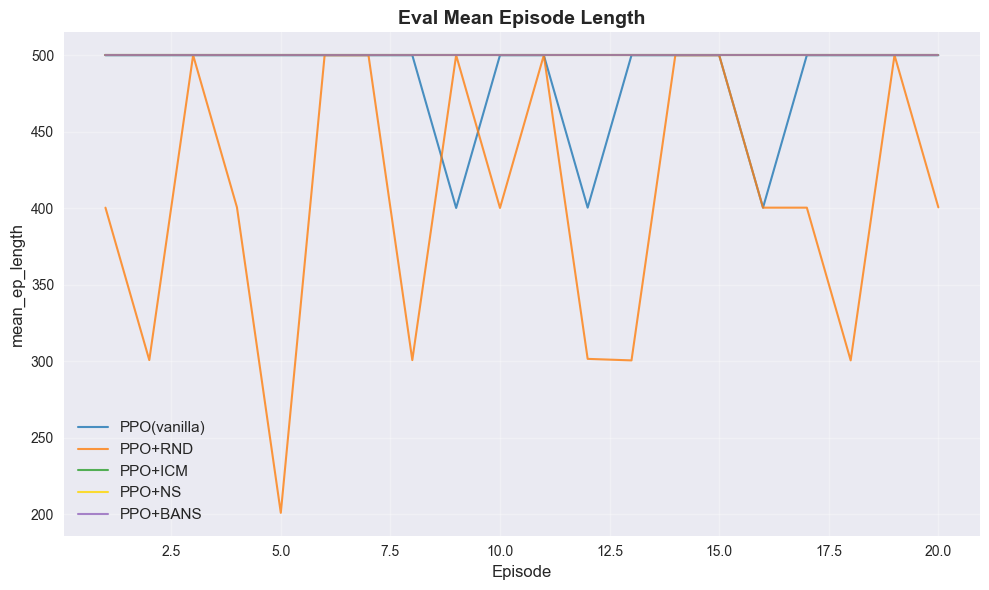

Plotting eval/mean_reward...


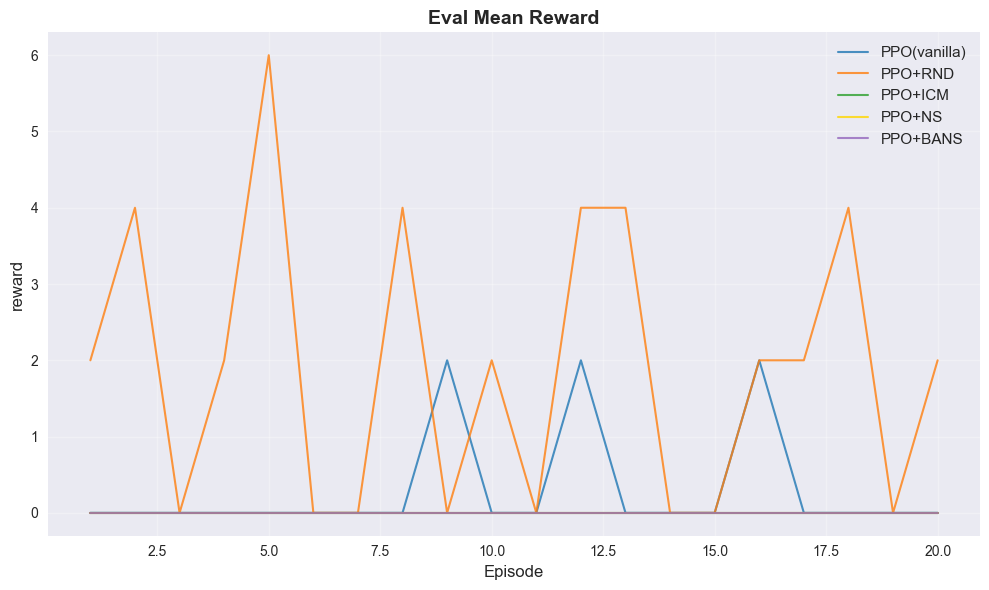


TIME

Plotting time/fps...


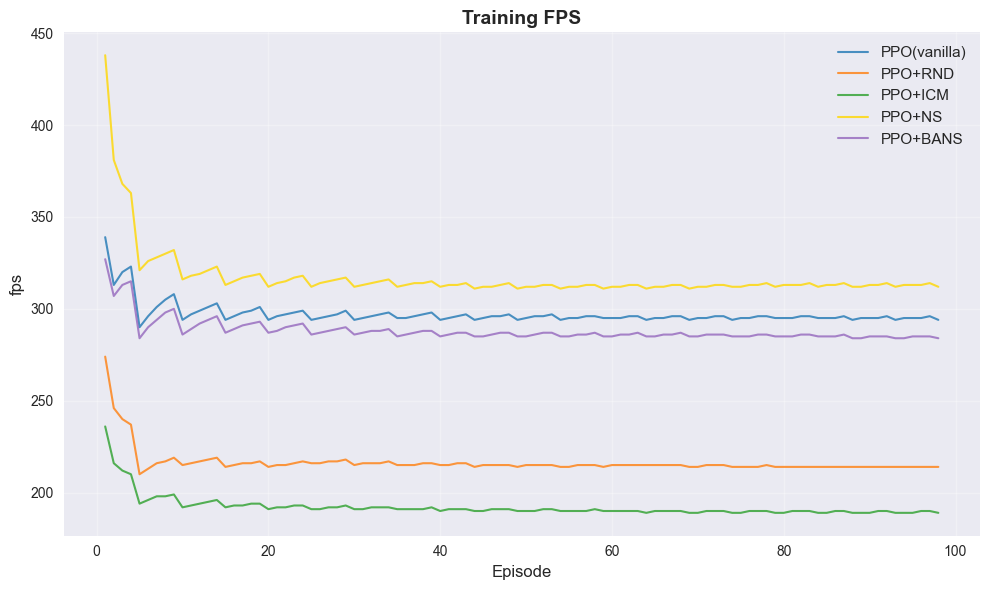


TRAIN

Plotting train/approx_kl...


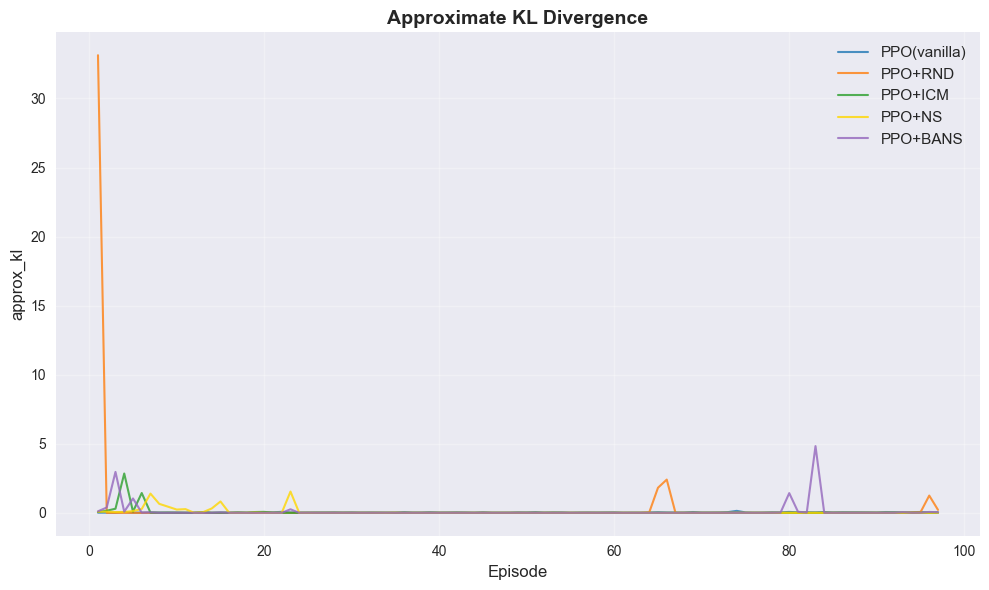

Plotting train/clip_fraction...


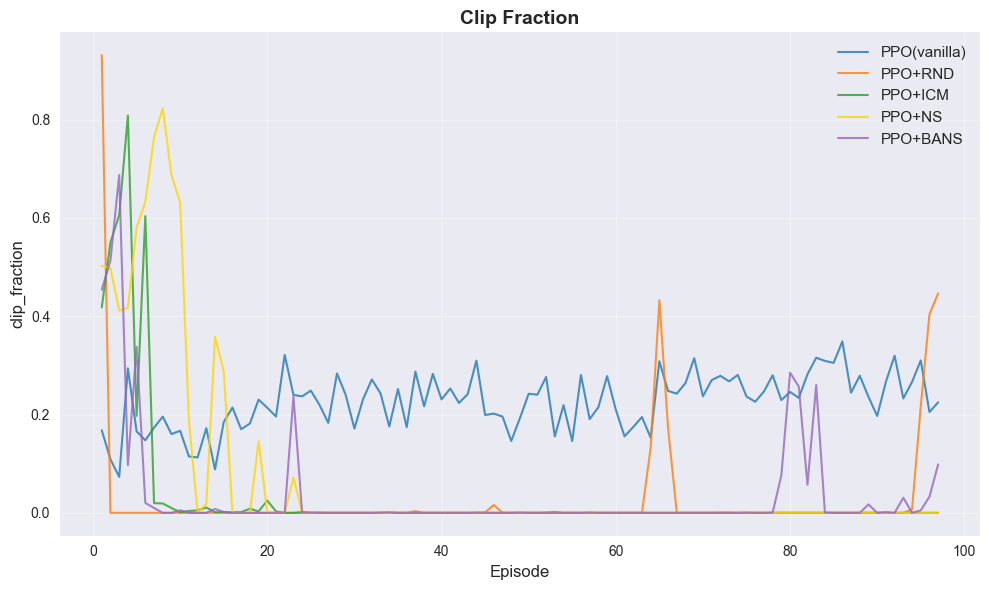

Plotting train/clip_range...


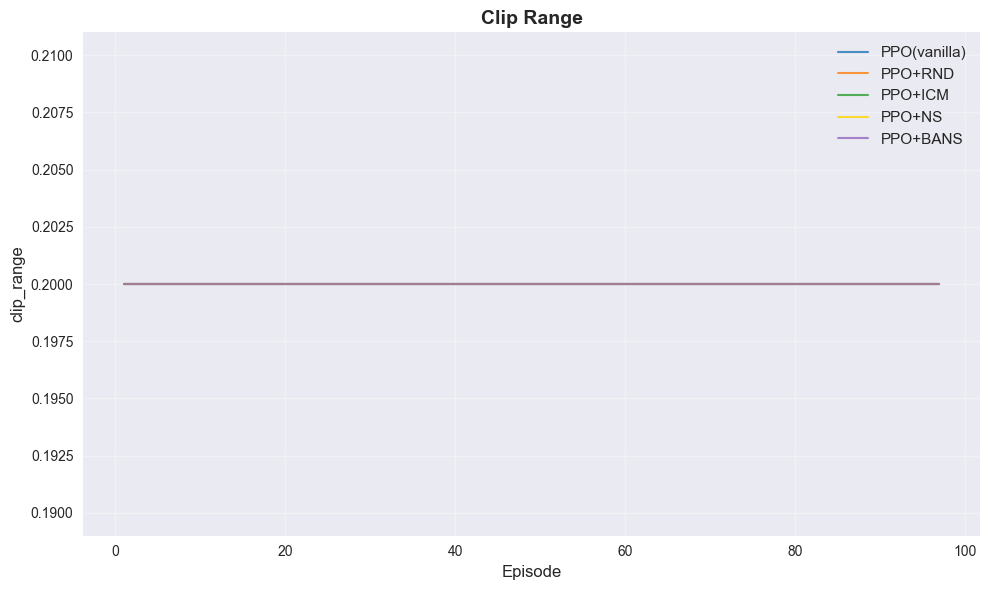

Plotting train/entropy_loss...


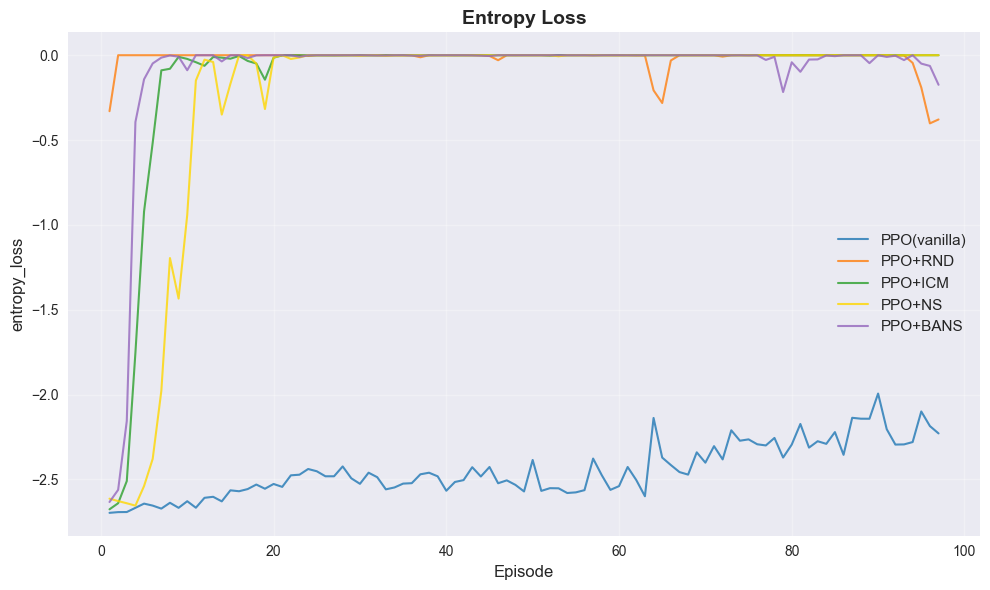

Plotting train/explained_variance...


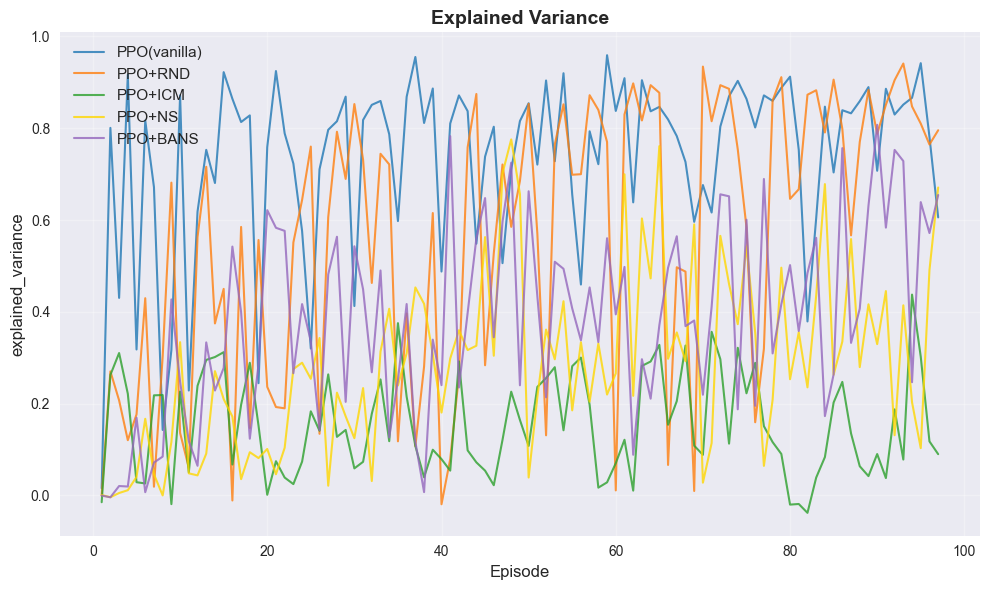

Plotting train/learning_rate...


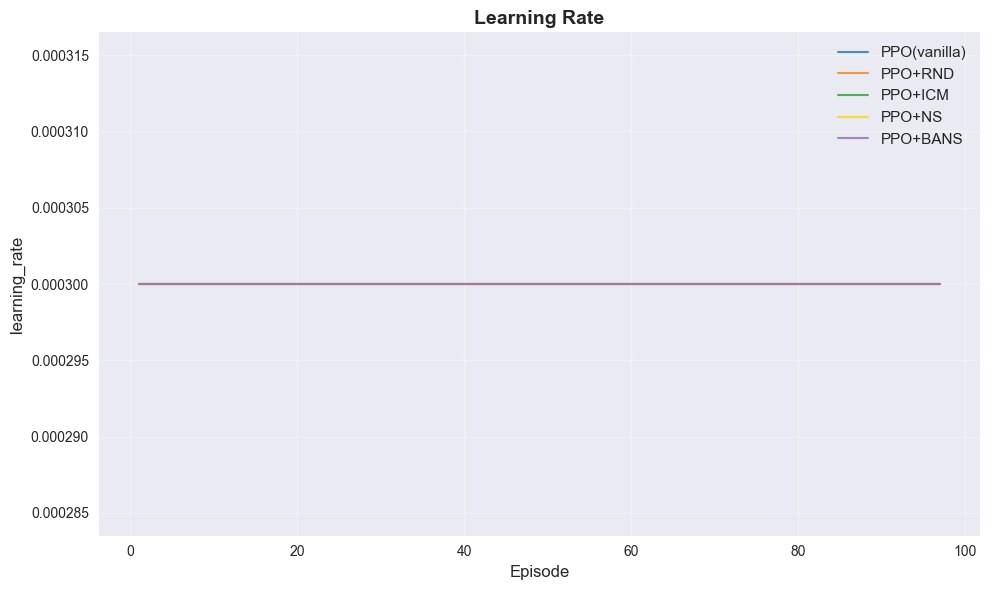

Plotting train/loss...


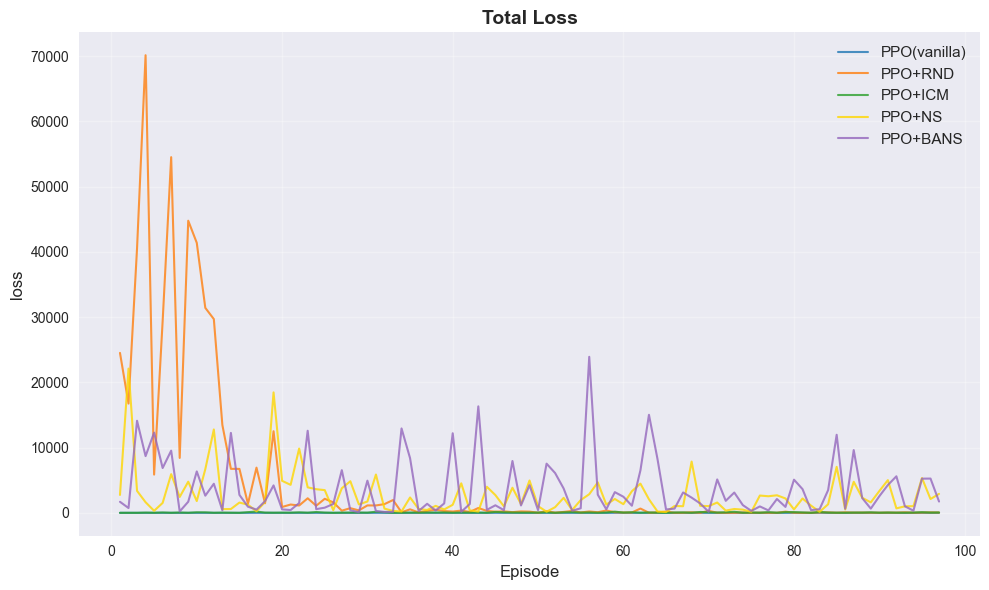

Plotting train/policy_gradient_loss...


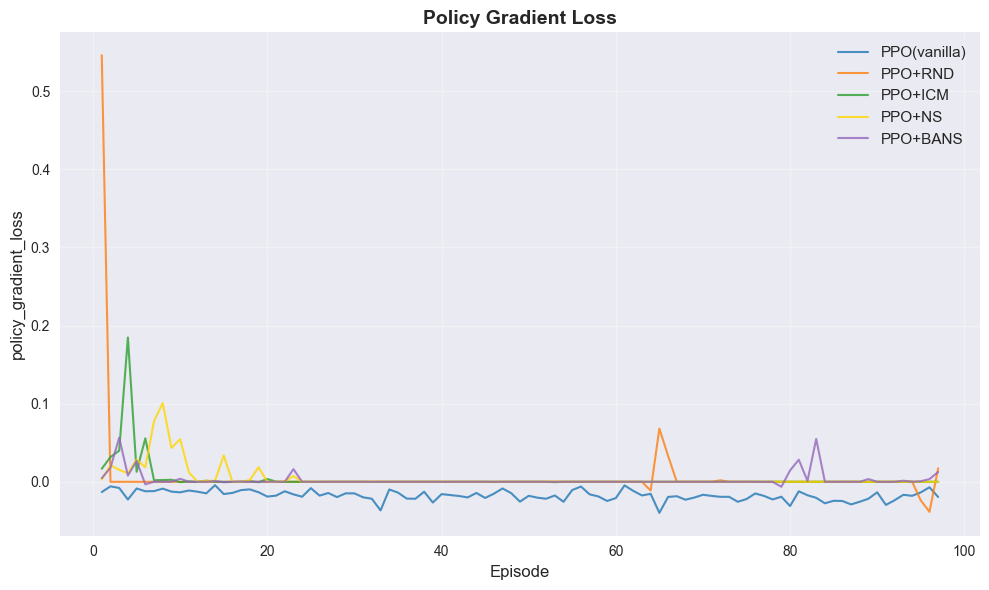

Plotting train/value_loss...


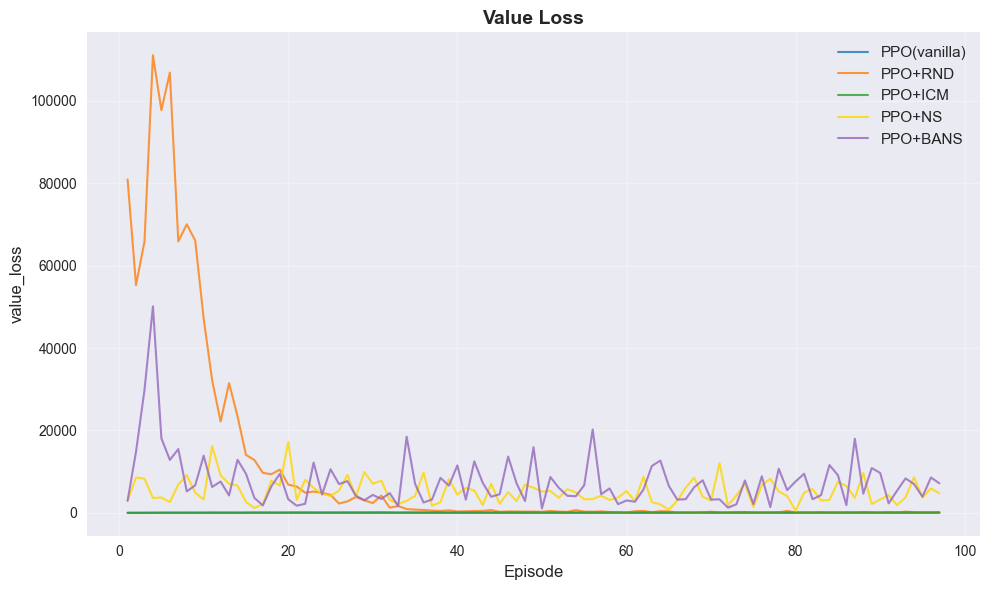

In [27]:
# ===== 定义要画的所有 tag（跟 TensorBoard 里的图一一对应） =====

groups = {
    "eval": [
        ("eval/mean_ep_length", "Eval Mean Episode Length", "mean_ep_length"),
        ("eval/mean_reward",    "Eval Mean Reward",         "reward"),
    ],
    "time": [
        ("time/fps", "Training FPS", "fps"),
    ],
    "train": [
        ("train/approx_kl",           "Approximate KL Divergence",           "approx_kl"),
        ("train/clip_fraction",       "Clip Fraction",                     "clip_fraction"),
        ("train/clip_range",          "Clip Range",                        "clip_range"),
        ("train/entropy_loss",        "Entropy Loss",                      "entropy_loss"),
        ("train/explained_variance",  "Explained Variance",                "explained_variance"),
        ("train/learning_rate",       "Learning Rate",                     "learning_rate"),
        ("train/loss",                "Total Loss",                        "loss"),
        ("train/policy_gradient_loss","Policy Gradient Loss",            "policy_gradient_loss"),
        ("train/value_loss",          "Value Loss",                        "value_loss"),
    ],
}

# ===== 一口气把所有图画出来（每个 tag 一张图） =====

for group_name, tag_list in groups.items():
    print(f"\n{'='*60}")
    print(f"{group_name.upper()}")
    print(f"{'='*60}\n")
    for tag, title, ylabel in tag_list:
        print(f"Plotting {tag}...")
        plot_tag_for_runs(
            tag=tag,
            runs_dict=RUNS,
            title=title,
            ylabel=ylabel,
        )
